# Titanic: valutare una spiegazione

Notebook di accompagnamento alla nota `appunti/approfondimenti/02_valutazione_xai_titanic.md` del cookbook (lezione del 27 febbraio 2026). Tre misure della lezione applicate allo stesso dataset: **fidelity** di un surrogato (misure di classe e di probabilità), **sanity check** per randomizzazione dei parametri e dei dati, **incremental feature deletion** globale e locale, con la baseline casuale.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from titanic_data import load_titanic, split, Encoder, feature_table, rate_by, group_metrics, DIED, SURVIVED

pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110
GRAY = "#7f7f7f"

df = load_titanic()
tr, te = split(df)                      # 70/30 stratificato, random_state=0
enc = Encoder().fit(tr)                 # mediana dell'età e moda del porto dal solo training
Xtr, Xte = enc.transform(tr), enc.transform(te)
ytr, yte = tr["Survived"].values, te["Survived"].values
cols = list(Xtr.columns)
print(f"{len(df)} passeggeri, sopravvissuti {df.Survived.sum()} ({df.Survived.mean():.3f})")
print(f"training {len(tr)} (tasso {ytr.mean():.3f}) · test {len(te)} (tasso {yte.mean():.3f})")
print(f"mediana età (training) {enc.age_median} · moda porto {enc.port_mode}")

891 passeggeri, sopravvissuti 342 (0.384)
training 623 (tasso 0.384) · test 268 (tasso 0.384)
mediana età (training) 28.75 · moda porto S


## 0. Il dataset

**891 passeggeri** del Titanic (copia `titanic.csv` di Data Science Dojo, uguale al training set Kaggle; l'equipaggio non c'è). **Target** `Survived`: 1 = sopravvissuto (342, 38,4%). Escluse: `PassengerId` (identificativo), `Name` (da cui si ricava `Title`), `Ticket` (quasi un identificativo), `Cabin` (mancante nel 77%).

Codifica numerica per i modelli (`titanic_data.Encoder`): `Sex_female` 0/1; `Age` con i mancanti sostituiti dalla mediana **del training** più l'indicatore `Age_missing`; `Embarked` one-hot (`Embarked_C`, `Embarked_Q`; S è la categoria di riferimento, i 2 mancanti diventano la moda S); `Pclass`, `SibSp`, `Parch`, `Fare` come numeri.

In [2]:
display(feature_table(df))
for c in ["Sex", "Pclass", "Embarked", "Title"]:
    display(rate_by(df, c).T)
display(df.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc=["size", "mean"]).round(3))

,feature,tipo,valori,mancanti
0,Pclass,ordinale,"1, 2, 3",0
1,Sex,nominale binaria,"female, male",0
2,Age,continua,"0.42–80, mediana 28",177
3,SibSp,conteggio,"0, 1, 2, 3, 4, 5, 8",0
4,Parch,conteggio,"0, 1, 2, 3, 4, 5, 6",0
5,Fare,continua,"0–512.329, mediana 14.4542",0
6,Embarked,nominale,"C, Q, S",2
7,Title,nominale (derivata),"Master, Miss, Mr, Mrs, Other",0
8,FamilySize,conteggio (derivata),"1, 2, 3, 4, 5, 6, 7, 8, 11",0


Sex,female,male
passeggeri,314.000,577.000
sopravvissuti,233.000,109.000
tasso,0.742,0.189


Pclass,1,2,3
passeggeri,216.00,184.000,491.000
sopravvissuti,136.00,87.000,119.000
tasso,0.63,0.473,0.242


Embarked,C,Q,S,mancante
passeggeri,168.000,77.00,644.000,2.0
sopravvissuti,93.000,30.00,217.000,2.0
tasso,0.554,0.39,0.337,1.0


Title,Master,Miss,Mr,Mrs,Other
passeggeri,40.000,182.000,517.000,125.000,27.000
sopravvissuti,23.000,127.000,81.000,99.000,12.000
tasso,0.575,0.698,0.157,0.792,0.444


size             mean              
Pclass    1    2    3      1      2      3
Sex                                       
female   94   76  144  0.968  0.921  0.500
male    122  108  347  0.369  0.157  0.135

## 1. Fidelity: quattro misure, quattro risposte

$f$ = random forest, $g$ = albero addestrato sulle predizioni di $f$. Agreement di classe, Pearson e MSE fra le probabilità $p_f$ e $p_g$, sul test (e l'agreement anche sul training).

In [3]:
from scipy.stats import pearsonr
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

rf = RandomForestClassifier(n_estimators=500, min_samples_leaf=3, random_state=0).fit(Xtr, ytr)
f_tr, f_te, pf = rf.predict(Xtr), rf.predict(Xte), rf.predict_proba(Xte)[:, 1]
rows = []
for d in range(1, 6):
    g = DecisionTreeClassifier(max_depth=d, random_state=0).fit(Xtr, f_tr)
    pg = g.predict_proba(Xte)[:, 1]
    rows.append({"profondità": d, "agreement test": np.mean(g.predict(Xte) == f_te), "agreement training": np.mean(g.predict(Xtr) == f_tr),
                 "Pearson(p_f, p_g)": pearsonr(pf, pg)[0], "MSE(p_f, p_g)": np.mean((pf - pg) ** 2)})
display(pd.DataFrame(rows).set_index("profondità").round(4))

,agreement test,agreement training,"Pearson(p_f, p_g)","MSE(p_f, p_g)"
profondità,,,,
1,0.8694,0.8539,0.7901,0.0428
2,0.8694,0.8587,0.8905,0.0270
3,0.9067,0.9101,0.9363,0.0227
4,0.9142,0.9197,0.9299,0.0280
5,0.9440,0.9374,0.9115,0.0404


Agreement e Pearson non sono ordinati allo stesso modo: la profondità 5 ha l'agreement più alto (0,944) ma Pearson e MSE peggiori della profondità 3. Il surrogato è addestrato sulle **classi** di $f$, quindi riproduce le decisioni meglio delle probabilità.

## 2. Il modello da spiegare e le attribuzioni

Regressione logistica sulle feature standardizzate. Attribuzione per il passeggero $i$: $a_{ij} = w_j z_{ij}$, contributo della feature $j$ al logit rispetto al passeggero medio del training ($z=0$).

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from scipy.stats import spearmanr

sc = StandardScaler().fit(Xtr); Ztr, Zte = sc.transform(Xtr), sc.transform(Xte)
lr = LogisticRegression(max_iter=1000).fit(Ztr, ytr); w = lr.coef_[0]
print(f"Acc training {lr.score(Ztr, ytr):.4f} · test {lr.score(Zte, yte):.4f} · intercetta {lr.intercept_[0]:.3f}")
display(pd.Series(w, index=cols, name="peso standardizzato").round(3).sort_values(key=np.abs, ascending=False).to_frame())

Acc training 0.7945 · test 0.8134 · intercetta -0.655


,peso standardizzato
Sex_female,1.256
Pclass,-0.899
Age,-0.507
SibSp,-0.396
Embarked_C,0.121
Age_missing,-0.113
Fare,0.113
Embarked_Q,0.073
Parch,0.006


## 3. Sanity check: randomizzare i parametri e i dati

**Randomizzazione a cascata dei parametri:** si sostituiscono con valori casuali i $k$ pesi più grandi in modulo e si confronta, passeggero per passeggero, il ranking delle attribuzioni originali con quello ricalcolato (Spearman, media su 27 passeggeri del test e 200 ripetizioni). Il metodo di confronto $b_{ij}=|z_{ij}|$ non usa i pesi e resta identico per costruzione.

**Randomizzazione dei dati:** si riaddestra il modello su etichette permutate.

,0,1,2,3,4,5,6,7,8,9
Spearman medio w·z,1.0,0.7588,0.532,0.376,0.3382,0.1809,0.0734,0.007,-0.0059,-0.0224


Etichette permutate (20 ripetizioni): Spearman medio 0.032 ± 0.334


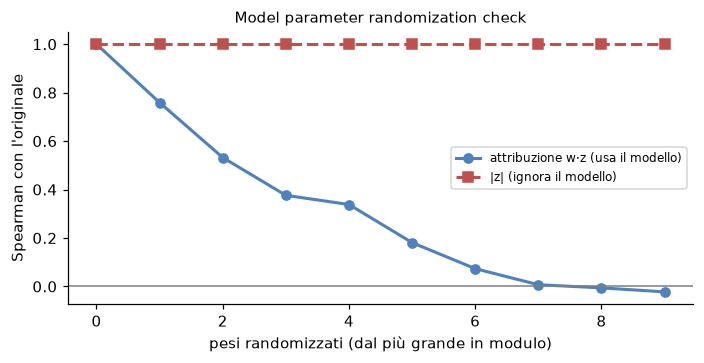

In [5]:
rng = np.random.default_rng(0)
order = np.argsort(-np.abs(w)); sub = range(0, len(Zte), 10)
casc = []
for k in range(len(w) + 1):
    vals = []
    for _ in range(200):
        w2 = w.copy(); w2[order[:k]] = rng.normal(0, np.abs(w).mean(), size=k)
        vals.append(np.mean([spearmanr(w * Zte[i], w2 * Zte[i])[0] for i in sub]))
    casc.append(np.nanmean(vals))
casc = pd.Series(casc, name="Spearman medio w·z"); display(casc.round(4).to_frame().T)

perm = []
for rep in range(20):
    lrp = LogisticRegression(max_iter=1000).fit(Ztr, rng.permutation(ytr))
    perm.append(np.mean([spearmanr(w * Zte[i], lrp.coef_[0] * Zte[i])[0] for i in range(len(Zte))]))
print(f"Etichette permutate (20 ripetizioni): Spearman medio {np.mean(perm):.3f} ± {np.std(perm):.3f}")

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(casc.index, casc.values, "o-", color=SURVIVED, lw=2, label="attribuzione w·z (usa il modello)")
ax.plot(casc.index, np.ones(len(casc)), "s--", color=DIED, lw=2, label="|z| (ignora il modello)")
ax.axhline(0, color=GRAY, lw=1)
ax.set_xlabel("pesi randomizzati (dal più grande in modulo)"); ax.set_ylabel("Spearman con l'originale")
ax.legend(fontsize=8); ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Model parameter randomization check", fontsize=10); plt.tight_layout(); plt.show()

## 4. Incremental feature deletion globale

Si «rimuovono» le feature sostituendole con la media del training ($z=0$) e si misura l'accuratezza sul test. Tre ordini: per importanza decrescente $|w_j|$, crescente, e casuale (media di 500 permutazioni).

ordine decrescente: ['Sex_female', 'Pclass', 'Age', 'SibSp', 'Embarked_C', 'Age_missing', 'Fare', 'Embarked_Q', 'Parch']


,0,1,2,3,4,5,6,7,8,9
decrescente,0.8134,0.7052,0.6679,0.6194,0.6231,0.6157,0.6157,0.6157,0.6157,0.6157
casuale,0.8134,0.7964,0.7796,0.7642,0.7465,0.7245,0.6967,0.6695,0.6415,0.6157
crescente,0.8134,0.8097,0.8060,0.8060,0.8172,0.8060,0.8172,0.7910,0.7910,0.6157


Area media: decrescente 0.6507 · casuale 0.7248 · crescente 0.7873


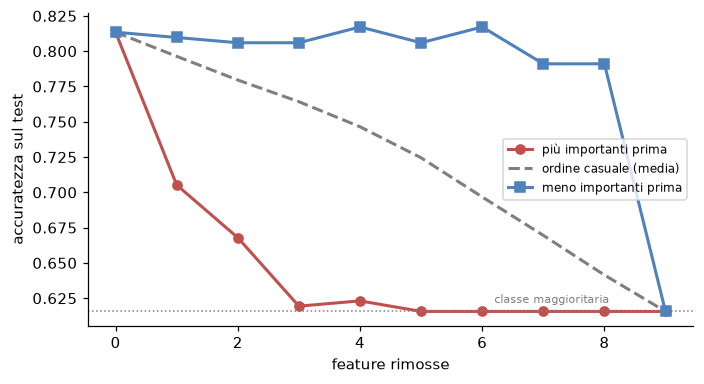

In [6]:
def acc_deleted(idx):
    Z = Zte.copy(); Z[:, list(idx)] = 0
    return np.mean(lr.predict(Z) == yte)

def curve(o):
    return np.array([acc_deleted(o[:k]) for k in range(len(o) + 1)])

desc, asc = np.argsort(-np.abs(w)), np.argsort(np.abs(w))
cd, ca = curve(desc), curve(asc)
cr = np.mean([curve(rng.permutation(len(w))) for _ in range(500)], axis=0)
print("ordine decrescente:", [cols[j] for j in desc])
display(pd.DataFrame({"decrescente": cd, "casuale": cr, "crescente": ca}).T.round(4))
print(f"Area media: decrescente {cd.mean():.4f} · casuale {cr.mean():.4f} · crescente {ca.mean():.4f}")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(cd, "o-", color=DIED, lw=2, label="più importanti prima")
ax.plot(cr, "--", color=GRAY, lw=2, label="ordine casuale (media)")
ax.plot(ca, "s-", color=SURVIVED, lw=2, label="meno importanti prima")
ax.axhline(1 - yte.mean(), color=GRAY, lw=1, ls=":"); ax.text(6.2, 1 - yte.mean() + 0.006, "classe maggioritaria", fontsize=7, color=GRAY)
ax.set_xlabel("feature rimosse"); ax.set_ylabel("accuratezza sul test"); ax.legend(fontsize=8)
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

## 5. Deletion locale: il segno delle attribuzioni

Un passeggero: Ruby Ford, 9 anni, terza classe, morta. Il modello le dà una probabilità di sopravvivere di 0,632. Rimuoviamo le feature una alla volta ordinandole per $|a_j|$ oppure per $a_j$ (prima i contributi positivi) e seguiamo la probabilità.

,Name,Sex,Pclass,Age,SibSp,Parch,Fare,Embarked,Survived
147,"Ford, Miss. Robina Maggie ""Ruby""",female,3,9.0,2,2,34.375,S,0


,Pclass,SibSp,Embarked_C,Embarked_Q,Fare,Parch,Age_missing,Age,Sex_female
a_j = w_j z_j,-0.759,-0.547,-0.058,-0.022,0.001,0.013,0.057,0.804,1.706


p = 0.632; passeggero medio p = 0.342
ordine per |a_j|: ['Sex_female', 'Age', 'Pclass', 'SibSp', 'Embarked_C', 'Age_missing', 'Embarked_Q', 'Parch', 'Fare']
   [0.632 0.238 0.122 0.23  0.34  0.353 0.34  0.345 0.342 0.342]
ordine per a_j (positivi prima): ['Sex_female', 'Age', 'Age_missing', 'Parch', 'Fare', 'Embarked_Q', 'Embarked_C', 'SibSp', 'Pclass']
   [0.632 0.238 0.122 0.116 0.115 0.115 0.117 0.123 0.196 0.342]


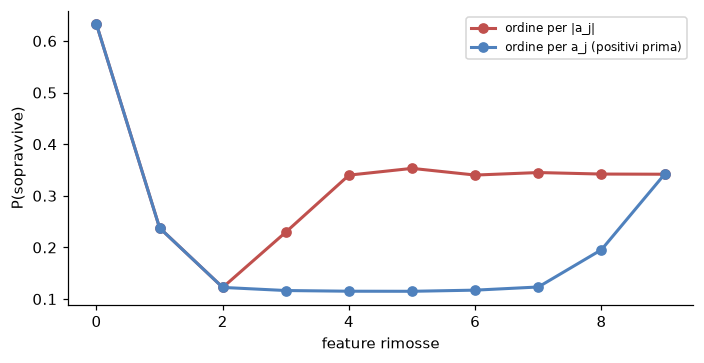

In [7]:
i = np.where(te.Name.str.startswith("Ford, Miss. Robina"))[0][0]
display(te.iloc[[i]][["Name", "Sex", "Pclass", "Age", "SibSp", "Parch", "Fare", "Embarked", "Survived"]])
a = w * Zte[i]
display(pd.Series(a, index=cols, name="a_j = w_j z_j").round(3).sort_values().to_frame().T)
prob = lambda z: lr.predict_proba(z.reshape(1, -1))[0, 1]
print(f"p = {prob(Zte[i]):.3f}; passeggero medio p = {prob(np.zeros(len(cols))):.3f}")
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for name, o, col in [("ordine per |a_j|", np.argsort(-np.abs(a)), DIED), ("ordine per a_j (positivi prima)", np.argsort(-a), SURVIVED)]:
    z = Zte[i].copy(); seq = [prob(z)]
    for j in o:
        z[j] = 0; seq.append(prob(z))
    print(f"{name}: {[cols[j] for j in o]}\n   {np.round(seq, 3)}")
    ax.plot(seq, "o-", color=col, lw=2, label=name)
ax.set_xlabel("feature rimosse"); ax.set_ylabel("P(sopravvive)"); ax.legend(fontsize=8)
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()